In [12]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/WikiDT_Persistent/')
FULL_IMAGE_DIR = ROOT / 'data' / 'images'
SUB_IMAGE_DIR = ROOT / 'data' / 'detection' / 'images'
QA_DIR = ROOT / 'QA_image' / 'data' / 'Train'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import pandas as pd

# Find and read the parquet file(s) in QA_DIR
parquet_files = list(QA_DIR.glob('*.parquet'))

if parquet_files:
    print(f"Reading parquet file: {parquet_files[0].name}")
    df = pd.read_parquet(parquet_files[0])
    display(df.head())
else:
    try:
        # Try loading the directory directly if parquet files are stored as partitioned dataset
        df = pd.read_parquet(QA_DIR)
        display(df.head())
    except Exception as e:
        print(f"Error reading parquet from {QA_DIR}: {e}")

Reading parquet file: data.parquet


,question,answer,context,pairs,positive_sentences,image
0,geno hayes and nick roach both played which po...,no answer,Position Player $ Free agency tag Date signed ...,"[{'label': 0, 'query': 'geno hayes and nick ro...",0,204_783_page.png
1,What is the number of bronze for Canada and si...,no answer,"Pos Team Time Gold Switzerland (Reto Götschi, ...","[{'label': 0, 'query': 'What is the number of ...",0,11338408_page.png
2,"What is Date, when Opponent is ""Philadelphia 7...",february 16,# Date H/A/N Opponent W/L Score Record 40 Janu...,"[{'label': 1, 'query': 'What is Date, when Opp...",1,16946097_page.png
3,Which Class has a Weight of 203?,sr,Position Number Name Height Weight Class Homet...,"[{'label': 1, 'query': 'Which Class has a Weig...",29,14624447_page.png
4,Who had 0 total votes in the purple team?,eliminated week 12 - the walk,Members Teammate Couples Team Blue Red 1 Blue ...,"[{'label': 1, 'query': 'Who had 0 total votes ...",1,18426579_page.png


In [14]:
import os

# Define the base path for images
IMAGE_BASE_PATH = '/content/drive/MyDrive/WikiDT_Persistent/data/images'

# Create the new column 'image_path' by joining the base path and the image filename
df['image_path'] = df['image'].apply(lambda x: os.path.join(IMAGE_BASE_PATH, str(x)) if pd.notnull(x) else None)

# Display the updated DataFrame to verify the new column
display(df[['image', 'image_path']].head())

,image,image_path
0,204_783_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,11338408_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
2,16946097_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
3,14624447_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
4,18426579_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...


In [15]:
# Show information about the columns (data types, non-null counts)
print("DataFrame Information:")
df.info()

# Display the first few rows showing all columns
print("\nFirst 5 rows of the full DataFrame:")
pd.set_option('display.max_columns', None)  # Ensure all columns are visible
display(df.head())

DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53492 entries, 0 to 53491
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   question            53492 non-null  object
 1   answer              53492 non-null  object
 2   context             53492 non-null  object
 3   pairs               53492 non-null  object
 4   positive_sentences  53492 non-null  int64 
 5   image               53492 non-null  object
 6   image_path          53492 non-null  object
dtypes: int64(1), object(6)
memory usage: 2.9+ MB

First 5 rows of the full DataFrame:


,question,answer,context,pairs,positive_sentences,image,image_path
0,geno hayes and nick roach both played which po...,no answer,Position Player $ Free agency tag Date signed ...,"[{'label': 0, 'query': 'geno hayes and nick ro...",0,204_783_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,What is the number of bronze for Canada and si...,no answer,"Pos Team Time Gold Switzerland (Reto Götschi, ...","[{'label': 0, 'query': 'What is the number of ...",0,11338408_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
2,"What is Date, when Opponent is ""Philadelphia 7...",february 16,# Date H/A/N Opponent W/L Score Record 40 Janu...,"[{'label': 1, 'query': 'What is Date, when Opp...",1,16946097_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
3,Which Class has a Weight of 203?,sr,Position Number Name Height Weight Class Homet...,"[{'label': 1, 'query': 'Which Class has a Weig...",29,14624447_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
4,Who had 0 total votes in the purple team?,eliminated week 12 - the walk,Members Teammate Couples Team Blue Red 1 Blue ...,"[{'label': 1, 'query': 'Who had 0 total votes ...",1,18426579_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...


In [16]:
# Define the save directory path
save_dir = ROOT / 'QA_image' / 'data' / 'Train'

# Ensure the target directory exists
save_dir.mkdir(parents=True, exist_ok=True)

# Define the output file path
output_file_path = save_dir / 'train_data_with_paths.parquet'

# Save the DataFrame to Parquet format
df.to_parquet(output_file_path, index=False)
print(f"DataFrame successfully saved to {output_file_path}")

DataFrame successfully saved to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Train/train_data_with_paths.parquet


In [17]:
import os
import pandas as pd

# Base image path
IMAGE_BASE_PATH = '/content/drive/MyDrive/WikiDT_Persistent/data/images'

# Define paths for Test and Val
test_dir = ROOT / 'QA_image' / 'data' / 'Test'
val_dir = ROOT / 'QA_image' / 'data' / 'Val'

for name, directory in [('Test', test_dir), ('Val', val_dir)]:
    # Find parquet files
    files = list(directory.glob('*.parquet'))
    if not files:
        print(f"No parquet file found in {directory}, trying directory direct load...")
        try:
            df_temp = pd.read_parquet(directory)
        except Exception as e:
            print(f"Could not load {name}: {e}")
            continue
    else:
        print(f"Reading parquet file for {name}: {files[0].name}")
        df_temp = pd.read_parquet(files[0])

    # Add the full image_path column
    df_temp['image_path'] = df_temp['image'].apply(lambda x: os.path.join(IMAGE_BASE_PATH, str(x)) if pd.notnull(x) else None)

    # Save the updated DataFrame in parquet format within its directory
    output_path = directory / 'data_with_paths.parquet'
    df_temp.to_parquet(output_path, index=False)
    print(f"Successfully saved {name} dataframe with image paths to {output_path}\n")

    # Store in global namespace as df_test and df_val
    if name == 'Test':
        df_test = df_temp
    else:
        df_val = df_temp

# Display the top rows of the processed Test DataFrame
print("Test DataFrame Preview:")
display(df_test.head(2))

# Display the top rows of the processed Val DataFrame
print("\nValidation DataFrame Preview:")
display(df_val.head(2))

Reading parquet file for Test: data.parquet
Successfully saved Test dataframe with image paths to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Test/data_with_paths.parquet

Reading parquet file for Val: data.parquet
Successfully saved Val dataframe with image paths to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Val/data_with_paths.parquet

Test DataFrame Preview:


,question,answer,context,pairs,positive_sentences,image,image_path
0,What are the title(s) of episodes directed by ...,buffy vs. dracula,No. overall No. in season Title Directed by Wr...,"[{'label': 0, 'query': 'What are the title(s) ...",1,28195971_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,who was the top driver at the 1967 british gra...,no answer,Pos No Driver Constructor Laps Time/Retired Gr...,"[{'label': 0, 'query': 'who was the top driver...",0,204_641_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...



Validation DataFrame Preview:


,question,answer,context,pairs,positive_sentences,image,image_path
0,when was the last year they placed 2nd?,no answer,No. Pos. Nation Player No. Pos. Nation Player ...,"[{'label': 0, 'query': 'when was the last year...",0,204_974_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,What was the sensor resolution with a minimal ...,355x288,"Stable release v2.2/October 7, 2008 Operating ...","[{'label': 0, 'query': 'What was the sensor re...",2,13751214_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...


In [18]:
# Save the Test DataFrame with the specific filename
test_output_file = test_dir / 'test_data_with_paths.parquet'
df_test.to_parquet(test_output_file, index=False)
print(f"Test DataFrame successfully saved to {test_output_file}")

# Save the Val DataFrame with the specific filename
val_output_file = val_dir / 'val_data_with_paths.parquet'
df_val.to_parquet(val_output_file, index=False)
print(f"Validation DataFrame successfully saved to {val_output_file}")

Test DataFrame successfully saved to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Test/test_data_with_paths.parquet
Validation DataFrame successfully saved to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Val/val_data_with_paths.parquet


In [19]:

%pip -q install transformers torch torchvision pillow pyarrow tqdm

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/WikiDT_Persistent")
FULL_IMAGE_DIR = ROOT / "data" / "images"

SPLIT_DIRS = {
    "train": ROOT / "QA_image/data/Train",
    "val": ROOT / "QA_image/data/Val",
    "test": ROOT / "QA_image/data/Test",
}

SPLIT_FILES = {
    "train": "train_data_with_paths.parquet",
    "val": "val_data_with_paths.parquet",
    "test": "test_data_with_paths.parquet",
}

datasets = {}

for split, folder in SPLIT_DIRS.items():
    path = folder / SPLIT_FILES[split]
    if not path.exists():
        raise FileNotFoundError(path)

    df_split = pd.read_parquet(path)

    # Reconstruct paths from the permanent Drive location
    df_split["image_path"] = df_split["image"].map(
        lambda name: str(FULL_IMAGE_DIR / str(name))
    )

    datasets[split] = df_split

    print(
        f"{split}: {len(df_split):,} records, "
        f"{df_split['image'].nunique():,} unique images"
    )


train: 53,492 records, 13,131 unique images
val: 6,686 records, 4,719 unique images
test: 6,687 records, 4,680 unique images


In [20]:

import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, ViTModel

MODEL_NAME = "google/vit-base-patch16-224-in21k"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = ViTModel.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()

class WikiDTImageDataset(Dataset):
    def __init__(self, dataframe, processor):
        self.df = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")
            pixel_values = self.processor(
                images=image,
                return_tensors="pt"
            )["pixel_values"].squeeze(0)

        return {
            "pixel_values": pixel_values,
            "image": row["image"]
        }


Device: cpu


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

In [21]:

from tqdm.auto import tqdm
import numpy as np

# Unique images, not duplicate QA rows
df_train_images = (
    datasets["train"]
    .drop_duplicates(subset=["image"])
    [["image", "image_path"]]
    .reset_index(drop=True)
)

# First experiment: 100 images
df_sample = df_train_images.head(100).copy()

image_dataset = WikiDTImageDataset(df_sample, processor)

loader = DataLoader(
    image_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

embeddings = []
image_names = []

with torch.inference_mode():
    for batch in tqdm(loader, desc="Generating ViT embeddings"):
        pixel_values = batch["pixel_values"].to(DEVICE)

        outputs = model(pixel_values=pixel_values)

        # CLS token embedding
        cls_embeddings = outputs.last_hidden_state[:, 0, :]

        embeddings.append(cls_embeddings.cpu().numpy())
        image_names.extend(batch["image"])

embeddings = np.concatenate(embeddings, axis=0)

print("Embedding shape:", embeddings.shape)
print("Images processed:", len(image_names))


Generating ViT embeddings:   0%|          | 0/13 [00:00<?, ?it/s]

Embedding shape: (100, 768)
Images processed: 100


In [22]:

EMBEDDING_DIR = ROOT / "embeddings" / "vit_base"
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)

df_embeddings = pd.DataFrame({
    "image": image_names,
    "embedding": [v.tolist() for v in embeddings]
})

output_path = EMBEDDING_DIR / "train_sample_100.parquet"

df_embeddings.to_parquet(output_path, index=False)

print("Saved:", output_path)
print("Embedding dimension:", len(df_embeddings.iloc[0]["embedding"]))


Saved: /content/drive/MyDrive/WikiDT_Persistent/embeddings/vit_base/train_sample_100.parquet
Embedding dimension: 768


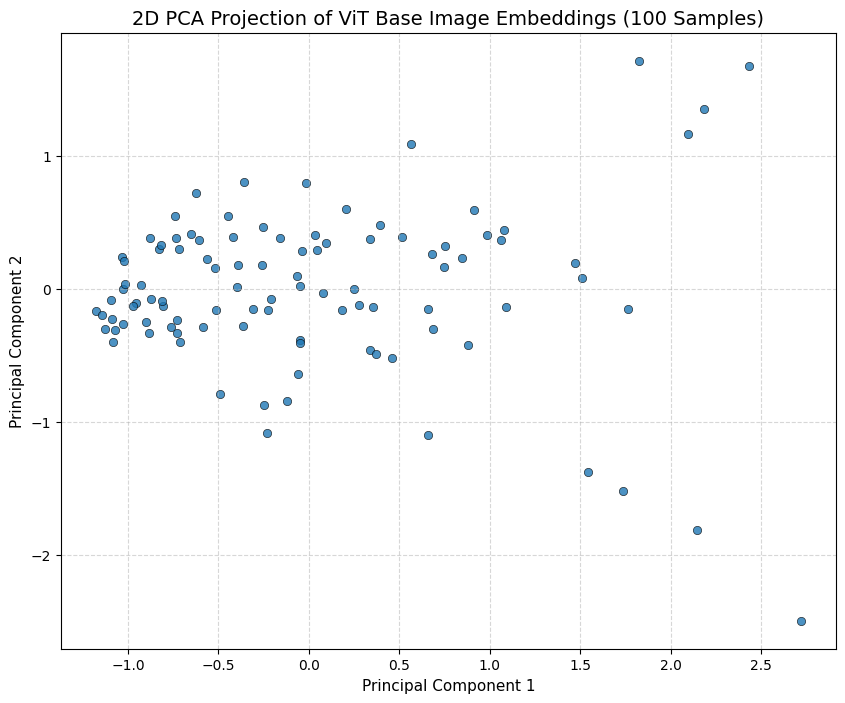

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

# Convert embeddings to a numpy array if not already
if isinstance(embeddings, list):
    embeddings_arr = np.array(embeddings)
else:
    embeddings_arr = embeddings

# Use PCA to project the 768-dimensional embeddings to 2D
pca = PCA(n_components=2, random_state=42)
embeddings_2d = pca.fit_transform(embeddings_arr)

# Create a DataFrame for easy plotting
plot_df = pd.DataFrame({
    'PCA 1': embeddings_2d[:, 0],
    'PCA 2': embeddings_2d[:, 1],
    'image_name': image_names
})

# Plot the embeddings
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PCA 1',
    y='PCA 2',
    data=plot_df,
    alpha=0.8,
    edgecolor='k'
)

plt.title('2D PCA Projection of ViT Base Image Embeddings (100 Samples)', fontsize=14)
plt.xlabel('Principal Component 1', fontsize=11)
plt.ylabel('Principal Component 2', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [25]:
# Display the image names alongside their 2D PCA projected vectors
print("First 10 images with their 2D PCA projected vectors:")
for idx, row in plot_df.head(10).iterrows():
    print(f"{row['image_name']}: [{row['PCA 1']:.4f}, {row['PCA 2']:.4f}]")

First 10 images with their 2D PCA projected vectors:
204_783_page.png: [0.5664, 1.0887]
11338408_page.png: [-1.0880, -0.2289]
16946097_page.png: [0.0762, -0.0313]
14624447_page.png: [-0.0629, 0.0974]
18426579_page.png: [-0.8790, 0.3835]
18225042_page.png: [1.5410, -1.3794]
1164217_page.png: [0.6785, 0.2607]
204_377_page.png: [0.2487, -0.0031]
13258876_page.png: [2.1832, 1.3557]
15354254_page.png: [-0.7146, -0.4023]


In [26]:
print(f"Raw ViT base embeddings shape: {embeddings.shape}")
print(f"Raw embeddings dimension (per image): {embeddings.shape[1]}")
print(f"Number of images processed: {embeddings.shape[0]}")
print(f"\n2D PCA projected embeddings shape: {embeddings_2d.shape}")

Raw ViT base embeddings shape: (100, 768)
Raw embeddings dimension (per image): 768
Number of images processed: 100

2D PCA projected embeddings shape: (100, 2)
